# Hessian-vector products

The Hessian $\mathbf H$ of the FWI misfit $J(\mathbf m)=\tfrac12\|\mathbf d(\mathbf m)-\mathbf d_{\rm obs}\|^2$
is never formed; what Newton-type optimizers, resolution analysis and uncertainty estimates need is
its action $\mathbf H\mathbf h$ on a direction $\mathbf h$. With the Jacobian
$\mathbf J=\partial\mathbf d/\partial\mathbf m$ and the residual $\mathbf r=\mathbf d-\mathbf d_{\rm obs}$,

$$\mathbf H\mathbf h=\mathbf J^{\mathsf T}\mathbf J\,\mathbf h+\sum_i r_i\,\frac{\partial^2 d_i}{\partial\mathbf m^2}\,\mathbf h ,$$

where the first term is the Gauss-Newton product and the second one vanishes when the data are fitted.

`sweep.autodiff.hessian_vector_product(prop, wavelet, sources, receivers, models, directions, loss, route=...)`
computes $\mathbf H\mathbf h$ of any twice-differentiable loss of the record in one call, by one of three
routes; a fourth, exact route for equations with a Born twin is written out in Section 7:

| route | what it computes | runs with | cost of one product |
|---|---|---|---|
| `route="double_backward"` | $\mathbf H\mathbf h$, exact | `impl='eager'`, `memory=Full()` or `Ckpt()`, `use_compile=False` | the autograd tape of the time loop and of its first backward |
| `route="forward"` | $\mathbf H\mathbf h$, exact | `impl='eager'`, `memory=Full()`, `use_compile=False` | one forward in dual numbers and its gradient |
| `route="difference"` | $\mathbf H\mathbf h$, to $O(\varepsilon^2)$ | every `impl` and memory strategy | two gradients |
| first-order gradient of the Born system | $\mathbf H\mathbf h$, exact | equations with a Born twin (`AcousticBorn`); `impl='c'` with `Full()` or `BoundarySaving()`, or compiled eager | one Born forward, one forward, and their gradients |

`route="auto"` (the default) takes `"forward"` where the propagator carries a tangent (the uncompiled
eager step with `Full()`) and `"difference"` everywhere else. The same module gives the Jacobian product
$\mathbf J\mathbf h$ (`jacobian_vector_product`), the Gauss-Newton product $\mathbf J^{\mathsf T}\mathbf J\mathbf h$
(`gauss_newton_vector_product`) and many products in one call (`hessian_vector_products`).

This notebook

1. computes the exact product by double backward and shows what that costs;
2. shows the paths that refuse `create_graph=True`, and their error;
3. computes $\mathbf J\mathbf h$ and the exact product in forward mode;
4. computes the product as a difference of two `impl='c'` gradients with boundary saving, and how to
   choose the step;
5. computes the Gauss-Newton product;
6. computes the exact product from first derivatives of the Born system, with `impl='c'` and with the
   compiled eager step;
7. compares the routes in accuracy, memory and time;
8. assembles the full Hessian and the Gauss-Newton matrix of a small model with
   `hessian_vector_products`, and looks at their diagonal and eigenvalues.

## 1. Model and data

In [1]:
import contextlib, sys, pathlib, time

_repo = pathlib.Path().resolve().parents[1]     # docs/notebooks/ -> repo root
if str(_repo / "src") not in sys.path:
    sys.path.insert(0, str(_repo / "src"))

import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.autodiff import (gauss_newton_vector_product, hessian_vector_product,
                            hessian_vector_products, jacobian_vector_product)
from sweep.equations import Acoustic, AcousticBorn
from sweep.operators.torch import slice_stencils
from sweep.propagator import BoundarySaving, Full, PropTorch
from sweep.propagator.options import EagerOptions

torch.backends.cudnn.allow_tf32 = False         # eager convolutions in fp32 on Ampere and later
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", torch.cuda.get_device_name() if device.type == "cuda" else "cpu")

device: Tesla V100-SXM2-32GB


In [2]:
nz, nx, dh = 100, 200, 10.0                     # 1 km deep x 2 km, 10 m grid
dt, nt, f0 = 1e-3, 1000, 10.0
abcn, order = 30, 4
z = np.arange(nz, dtype=np.float32)[:, None] * dh + np.zeros((1, nx), np.float32)
x = np.arange(nx, dtype=np.float32)[None, :] * dh + np.zeros((nz, 1), np.float32)

v0 = (1600.0 + 0.8 * z).astype(np.float32)                                   # initial model
v_true = (v0 + 150.0 * np.exp(-((z - 500) ** 2 + (x - 1000) ** 2) / (2 * 80.0 ** 2))).astype(np.float32)

src_x = np.arange(20, nx - 20, 40)              # 4 shots every 400 m
nshots = len(src_x)
sources = np.stack([src_x, np.full(nshots, 2)], 1)                           # (x, z)
rec_x = np.arange(2, nx - 2, 2)                 # 98 receivers every 20 m
receivers = np.repeat(np.stack([rec_x, np.full_like(rec_x, 2)], 1)[None], nshots, 0)

t = np.arange(nt) * dt
a = (np.pi * f0 * (t - 1.2 / f0)) ** 2
T = lambda arr: torch.tensor(arr, device=device)
w = T(((1 - 2 * a) * np.exp(-a)).astype(np.float32))                         # Ricker, 10 Hz
m0 = T(v0)


def acoustic(impl, memory):
    kw = dict(shape=(nz, nx), dh=dh, dt=dt, nt=nt, abcn=abcn, impl=impl, memory=memory,
              source_type=["h1"], receiver_type=["h1"], dev=device)
    if impl == "eager":
        kw["eager_options"] = EagerOptions(use_compile=False)
    return PropTorch(Acoustic(spatial_order=order, device=device), **kw)


c_bs = acoustic("c", BoundarySaving())
with torch.no_grad():
    d_obs = c_bs(w, sources, receivers, models=[T(v_true)])
print("observed data (shots, nt, receivers, 1):", tuple(d_obs.shape))


def loss(d):
    return 0.5 * ((d - d_obs) ** 2).sum()


def misfit(prop, m):
    return loss(prop(w, sources, receivers, models=[m]))


def hvp(prop, h, **kw):
    # H h of the misfit at m0 along h
    return hessian_vector_product(prop, w, sources, receivers, [m0], [h], loss, **kw)[0]


rel = lambda a_, b_: float((a_ - b_).norm() / b_.norm())

observed data (shots, nt, receivers, 1): (4, 1000, 98, 1)


We use two directions. $\mathbf h_{\rm psf}$ is a small Gaussian at the centre of the anomaly, so
$\mathbf H\mathbf h_{\rm psf}$ is the point-spread function of the Hessian there. $\mathbf h_{\rm rand}$ is
white noise, which weights every scale of the model. Both are zero on the two outermost rings of
cells: the model is extended into the absorbing layer by repeating its edge cells, so the gradient
of an outermost cell collects that layer, and for a direction on the outermost ring forward mode
and a difference of gradients give a product that differs from the double backward.

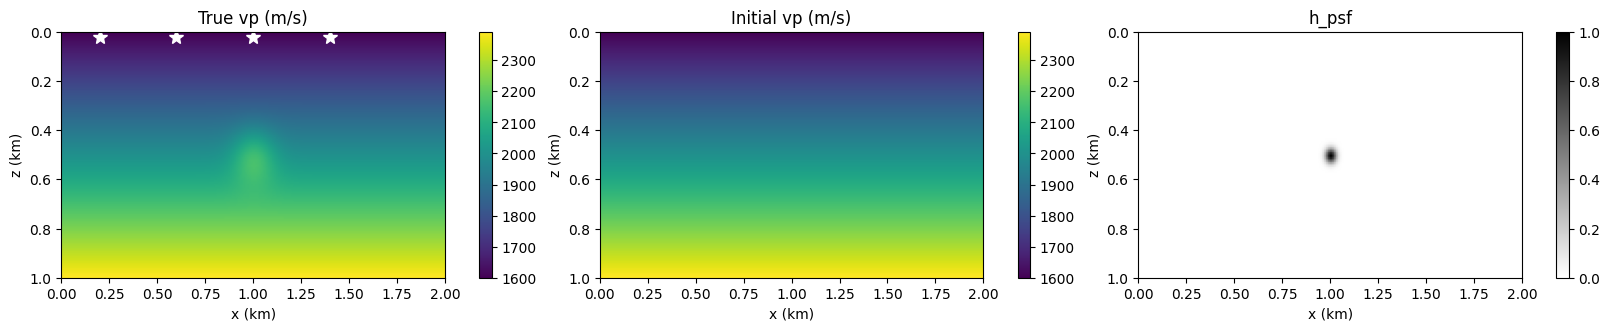

In [3]:
h_psf = T(np.exp(-((z - 500) ** 2 + (x - 1000) ** 2) / (2 * 20.0 ** 2)).astype(np.float32))
ring = torch.zeros(nz, nx, device=device)
ring[2:-2, 2:-2] = 1.0
h_rand = torch.randn(nz, nx, generator=torch.Generator().manual_seed(0)).to(device) * ring

extent = [0, nx * dh / 1e3, nz * dh / 1e3, 0]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.2), constrained_layout=True)
vrange = dict(vmin=float(v_true.min()), vmax=float(v_true.max()))          # one scale for both models
for a_, img, title, kw in [(ax[0], v_true, "True vp (m/s)", dict(cmap="viridis", **vrange)),
                           (ax[1], v0, "Initial vp (m/s)", dict(cmap="viridis", **vrange)),
                           (ax[2], h_psf.cpu().numpy(), "h_psf", dict(cmap="gray_r"))]:
    im = a_.imshow(img, extent=extent, aspect="auto", **kw)
    a_.set_title(title); a_.set_xlabel("x (km)"); a_.set_ylabel("z (km)")
    fig.colorbar(im, ax=a_)
ax[0].plot(src_x * dh / 1e3, np.full(nshots, 0.02), "w*", ms=10)
plt.show()

## 2. Exact product by double backward

The uncompiled eager step is plain PyTorch, so autograd can differentiate the gradient once more:
`route="double_backward"` takes the gradient with `create_graph=True` and differentiates
$\mathbf g\cdot\mathbf h$. The requirements are

* `impl='eager'` with `eager_options=EagerOptions(use_compile=False)`: torch.compile builds the
  step's backward without a double backward;
* `memory=Full()` or `memory=Ckpt()`: `create_graph=True` keeps the recomputed chunks on the tape,
  so checkpointing does not reduce the memory here;
* `torch.backends.cudnn.allow_tf32 = False` on Ampere and later GPUs: in TF32 the product is off by
  several percent.

From four shots per call up, the double backward runs the stencils as shifted slices instead of
convolutions (`sweep.operators.torch.slice_stencils`), whose second derivative is faster than a
convolution's.

In [4]:
eager = acoustic("eager", Full())


def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


def measure(fn, repeat=1):
    # fn's last result, seconds per call and peak memory (MiB) above what was in use at the start
    if device.type == "cuda":
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    start = torch.cuda.memory_allocated() if device.type == "cuda" else 0
    sync(); t0 = time.perf_counter()
    for _ in range(repeat):
        out = fn()
    sync()
    sec = (time.perf_counter() - t0) / repeat
    mib = (torch.cuda.max_memory_allocated() - start) / 2**20 if device.type == "cuda" else float("nan")
    return out, sec, mib


hv_exact, cost = {}, {}
for name, h in [("psf", h_psf), ("rand", h_rand)]:
    hv_exact[name], sec, mib = measure(lambda: hvp(eager, h, route="double_backward"))
    print(f"H h_{name}, double backward: {sec:.1f} s, peak {mib:.0f} MiB")
cost["double backward"] = (sec, mib)

H h_psf, double backward: 8.2 s, peak 5295 MiB


H h_rand, double backward: 7.5 s, peak 5294 MiB


## 3. The paths that refuse `create_graph=True`

`impl='c'`, eager boundary saving, the compiled eager step, domain decomposition and registered
gradient-mode imaging conditions compute their backward outside the autograd tape. Under
`create_graph=True` they raise at once and say what works; a gradient without a graph would
otherwise fail later, or return only the Hessian of a regularizer on the tape. On these propagators
`hessian_vector_product` takes the difference route of Section 5 (`route="auto"`).

In [5]:
for name, prop in [("impl='c'", c_bs), ("eager + BoundarySaving()", acoustic("eager", BoundarySaving()))]:
    m = m0.clone().requires_grad_(True)
    try:
        torch.autograd.grad(misfit(prop, m), m, create_graph=True)
    except RuntimeError as err:
        print(f"{name}:\n  {str(err)[:230]}...\n")

impl='c':
  impl='c' gives first derivatives only and is not twice-differentiable: its backward is the compiled adjoint, which autograd cannot differentiate again. create_graph=True (Hessian-vector products, higher-order gradients) needs the ...



eager + BoundarySaving():
  impl='eager' with memory=BoundarySaving() gives first derivatives only and is not twice-differentiable: its backward reconstructs each step's input from the saved boundary and re-runs the step on detached copies. create_graph=True...



## 4. Forward mode

Forward-mode AD carries the direction through the uncompiled eager step with `memory=Full()`: the
model enters as the dual number $\mathbf m+\epsilon\mathbf h$ with $\epsilon^2=0$, and the tangent of the
record is $\mathbf J\mathbf h$, the Born record of $\mathbf h$, without a Born equation
(`jacobian_vector_product`). With $\mathbf s=\mathbf J\mathbf h$ and the residual $\mathbf r$ held
fixed in turn, the scalar

$$\psi(\mathbf m)=\langle\mathbf d(\mathbf m),\,\mathbf s\rangle+\langle\mathbf J(\mathbf m)\mathbf h,\,\mathbf r\rangle$$

has the gradient

$$\nabla\psi=\mathbf J^{\mathsf T}\mathbf s+\Big(\frac{\partial(\mathbf J\mathbf h)}{\partial\mathbf m}\Big)^{\mathsf T}\mathbf r
=\mathbf J^{\mathsf T}\mathbf J\mathbf h+\sum_i r_i\,\frac{\partial^2 d_i}{\partial\mathbf m^2}\,\mathbf h=\mathbf H\mathbf h .$$

`route="forward"` takes this gradient through the forward in dual numbers (reverse over forward),
with first derivatives only. For a general loss, $\mathbf r$ is the gradient of the loss with respect
to the record. `gauss_newton_vector_product` keeps the first term; on this propagator it takes
$\mathbf J\mathbf h$ in forward mode too, so it gives the exact Gauss-Newton product that Section 6
checks the Born route against.

In [6]:
(_, jh_exact), sec, mib = measure(
    lambda: jacobian_vector_product(eager, w, sources, receivers, [m0], [h_psf], route="forward"))
print(f"J h_psf, forward mode: {sec:.1f} s, peak {mib:.0f} MiB")
(hv_forward,), sec, mib = measure(lambda: [hvp(eager, h_psf, route="forward")])
cost["reverse over forward"] = (sec, mib)
print(f"H h_psf, reverse over forward: {sec:.1f} s, peak {mib:.0f} MiB, "
      f"{rel(hv_forward, hv_exact['psf']):.1e} off the double backward")
(gn_exact,) = gauss_newton_vector_product(eager, w, sources, receivers, [m0], [h_psf], loss, route="forward")

J h_psf, forward mode: 11.3 s, peak 36 MiB


H h_psf, reverse over forward: 25.5 s, peak 3340 MiB, 2.9e-06 off the double backward


## 5. Difference of two gradients

The central difference

$$\mathbf H\mathbf h\approx\frac{\mathbf g(\mathbf m+\varepsilon\mathbf h)-\mathbf g(\mathbf m-\varepsilon\mathbf h)}{2\varepsilon}$$

needs two gradients and nothing else, so `route="difference"` runs with `impl='c'` and boundary
saving at the memory of one gradient. The step follows from `rel_step` (default $10^{-2}$):
$\varepsilon$ changes no model by more than `rel_step` of its peak, so the largest velocity change
$\varepsilon\max|\mathbf h|$ is `rel_step` $\times\max\mathbf m$. The error has two parts: the truncation
error, which grows as $\varepsilon^2$, and the single-precision round-off of the gradients, which grows
as $1/\varepsilon$. We scan `rel_step` against the exact products of Section 2.

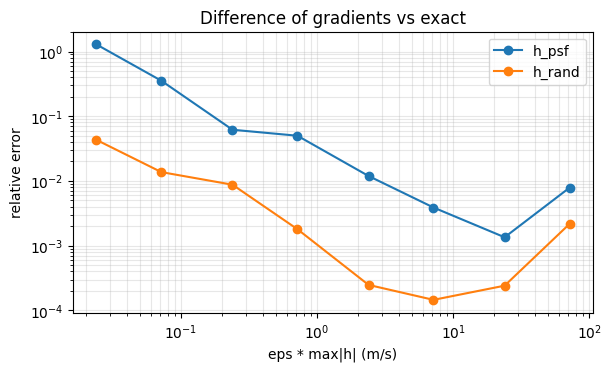

h_psf: best rel_step 1e-02 (24 m/s), relative error 1.3e-03; default 1e-2 (24 m/s): 1.3e-03
h_rand: best rel_step 3e-03 (7 m/s), relative error 1.5e-04; default 1e-2 (24 m/s): 2.4e-04


In [7]:
steps = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2]
errors = {name: [rel(hvp(c_bs, h, route="difference", rel_step=s), hv_exact[name]) for s in steps]
          for name, h in [("psf", h_psf), ("rand", h_rand)]}
vpeak = float(m0.max())

fig, ax = plt.subplots(figsize=(6, 3.6), constrained_layout=True)
for name in errors:
    ax.loglog([s * vpeak for s in steps], errors[name], "o-", label=f"h_{name}")
ax.set_xlabel("eps * max|h| (m/s)"); ax.set_ylabel("relative error")
ax.set_title("Difference of gradients vs exact"); ax.grid(True, which="both", alpha=0.3); ax.legend()
plt.show()
for name in errors:
    best = int(np.argmin(errors[name]))
    print(f"h_{name}: best rel_step {steps[best]:.0e} ({steps[best] * vpeak:.0f} m/s), relative error "
          f"{errors[name][best]:.1e}; default 1e-2 ({1e-2 * vpeak:.0f} m/s): {errors[name][steps.index(1e-2)]:.1e}")

As shown in the figure, the error first falls as $1/\varepsilon$ (round-off) and then rises as $\varepsilon^2$
(truncation). It is smallest when the largest velocity change $\varepsilon\max|\mathbf h|$ is about ten to a few
tens of m/s, 0.3 to 1 % of the velocity here, where the product agrees with the exact one to about
$10^{-3}$ for $\mathbf h_{\rm psf}$ and $10^{-4}$ for $\mathbf h_{\rm rand}$. The default `rel_step` of $10^{-2}$
(24 m/s here) is the best step for $\mathbf h_{\rm psf}$ and within a factor of two of the best error for
$\mathbf h_{\rm rand}$. The minimum depends on the direction and the model, so for a new problem we
recommend a short scan of this kind, with two or three values of `rel_step`, before choosing the step.

## 6. Gauss-Newton product

`gauss_newton_vector_product` drops the residual term: it takes $\mathbf J\mathbf h$ (in forward mode on
the uncompiled eager step, as a central difference of two forwards elsewhere) and one gradient with
$\mathbf J\mathbf h$ in place of the residual. The product is positive semi-definite, which is what the
conjugate-gradient inner loop of a Gauss-Newton method needs.

For `Acoustic`, the Born equation gives $\mathbf J\mathbf h$ exactly with `impl='c'`. `AcousticBorn` steps
the background field and the scattered field of the same scheme together, and its scattered step is
the derivative of the `Acoustic` step. Its perturbation `mp` is the relative change of $v^2$, so a
velocity direction $\mathbf h$ enters as `mp` $=2\mathbf h/\mathbf m$, and its record is $\mathbf J\mathbf h$. A
gradient with that record in place of the residual gives $\mathbf J^{\mathsf T}\mathbf J\mathbf h$; both steps
run with `impl='c'` and boundary saving.

In [8]:
def acoustic_born():
    return PropTorch(AcousticBorn(spatial_order=order, device=device), shape=(nz, nx), dh=dh, dt=dt,
                     nt=nt, abcn=abcn, impl="c", memory=BoundarySaving(), source_type=["h1"],
                     receiver_type=["sh1"], dev=device)


born = acoustic_born()


def jacobian_product(h, born=born):
    with torch.no_grad():
        return born(w, sources, receivers, models=[m0, 2 * h / m0])


def hv_gauss_newton(h, prop=c_bs, born=born):
    m = m0.clone().requires_grad_(True)
    rec = prop(w, sources, receivers, models=[m])
    return torch.autograd.grad(rec, m, grad_outputs=jacobian_product(h, born))[0]


(gn_c,) = gauss_newton_vector_product(c_bs, w, sources, receivers, [m0], [h_psf], loss)   # J h by differences
print("J h_psf, Born vs forward mode:                       %.1e" % rel(jacobian_product(h_psf), jh_exact))
print("J^T J h_psf, Born route vs exact:                    %.1e" % rel(hv_gauss_newton(h_psf), gn_exact))
print("J^T J h_psf, gauss_newton_vector_product, impl='c':  %.1e" % rel(gn_c, gn_exact))
print("J^T J h_psf vs full H h_psf:                         %.1e  (the residual term)" % rel(gn_exact, hv_exact["psf"]))

J h_psf, Born vs forward mode:                       1.7e-04


J^T J h_psf, Born route vs exact:                    1.4e-04
J^T J h_psf, gauss_newton_vector_product, impl='c':  1.5e-03
J^T J h_psf vs full H h_psf:                         3.6e-02  (the residual term)


## 7. Exact product from first derivatives of the Born system

The forward-mode identity of Section 4 holds with any $\mathbf J(\mathbf m)\mathbf h$ that is a function of
the model on the autograd tape. With a Born equation, $\mathbf J(\mathbf m)\mathbf h$ is the Born record, so
the second term of $\nabla\psi$ is the gradient of the Born data with respect to the background
velocity, which `AcousticBorn` returns with `impl='c'` in the full and boundary-saving modes. The
direction enters through `mp = 2h/m`, which depends on $\mathbf m$ as well; autograd takes that
dependence into account when `mp` is computed from the model tensor. Only first derivatives are
taken, so the route runs with `impl='c'`, with boundary saving, and with the compiled eager step. It
costs one Born forward, one forward and their two backwards. This is the second-order adjoint
method: deepwave computes the same two extra wavefields in the double backward of its scalar
propagator. The eager `AcousticBorn` takes the first derivatives of `Acoustic`'s CPML, so the
compiled eager product agrees with the double backward to round-off. The `impl='c'` kernels of the
2-D `AcousticBorn` take the CPML term $\partial_x(a\psi)$ by the product rule where those of `Acoustic`
take one fused stencil, which leaves the `impl='c'` products about $10^{-4}$ off here, more in a
thinner PML.

In [9]:
def hv_born_system(h, prop, born):
    m = m0.clone().requires_grad_(True)
    s = born(w, sources, receivers, models=[m, 2 * h / m])      # J h, on the tape of m
    d = prop(w, sources, receivers, models=[m])
    psi = (d * s.detach()).sum() + (s * (d - d_obs).detach()).sum()
    return torch.autograd.grad(psi, m)[0]


def eager_compiled(equation, receiver):
    return PropTorch(equation(spatial_order=order, device=device), shape=(nz, nx), dh=dh, dt=dt, nt=nt,
                     abcn=abcn, impl="eager", memory=Full(), source_type=["h1"],
                     receiver_type=[receiver], dev=device, eager_options=EagerOptions(use_compile=True))


hv_bs = {name: hv_born_system(h, c_bs, born) for name, h in [("psf", h_psf), ("rand", h_rand)]}
for name in hv_bs:
    print(f"h_{name}: impl='c' + BoundarySaving vs double backward: {rel(hv_bs[name], hv_exact[name]):.1e}")
if device.type == "cuda":
    eager_pair = (eager_compiled(Acoustic, "h1"), eager_compiled(AcousticBorn, "sh1"))
    hv_compiled = hv_born_system(h_psf, *eager_pair)
    print(f"h_psf: compiled eager vs double backward:          {rel(hv_compiled, hv_exact['psf']):.1e}")

h_psf: impl='c' + BoundarySaving vs double backward: 1.5e-04
h_rand: impl='c' + BoundarySaving vs double backward: 1.3e-05


sweep: torch.compile is compiling 4 AcousticBorn steps per call for 4 shots on a 100x200 grid (with gradients); the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


sweep: torch.compile is compiling 4 Acoustic steps per call for 4 shots on a 100x200 grid (with gradients)


h_psf: compiled eager vs double backward:          4.7e-06


## 8. Comparison

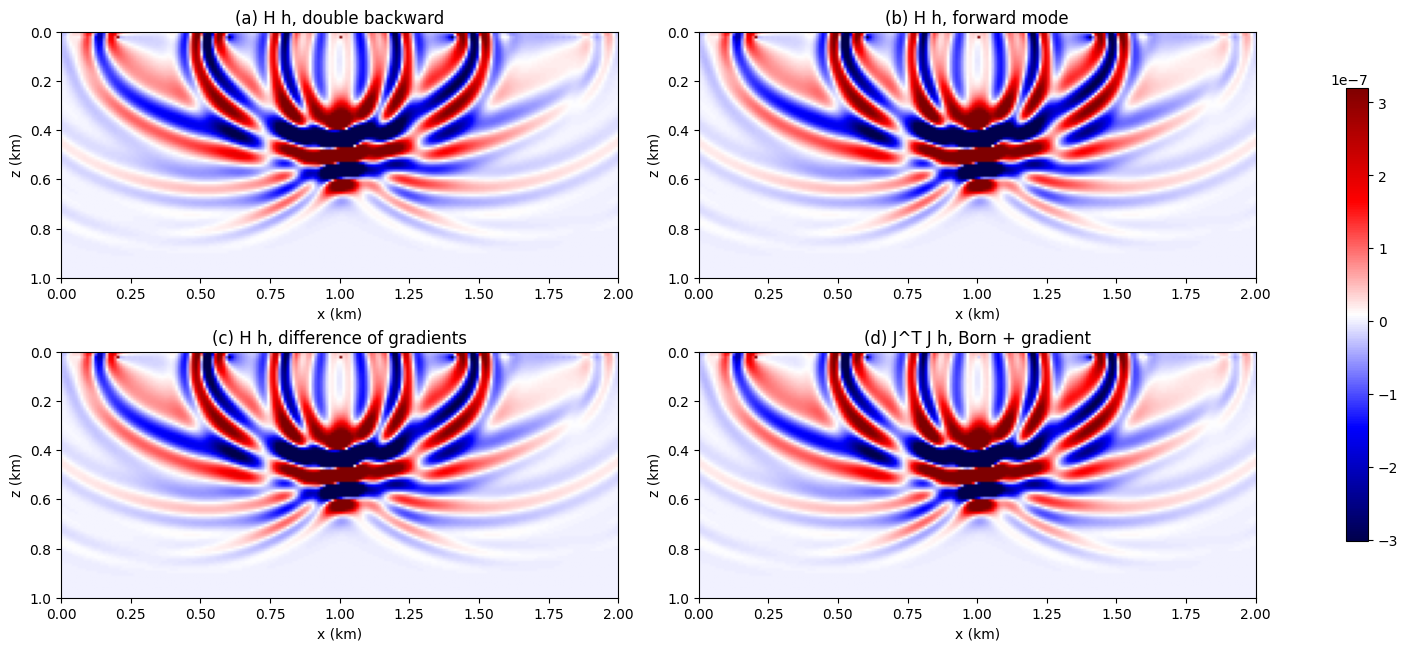

In [10]:
hv_fd = hvp(c_bs, h_psf, route="difference")                  # the default rel_step, 1e-2
hv_gn = hv_gauss_newton(h_psf)

panels = [(hv_exact["psf"], "(a) H h, double backward"),
          (hv_forward, "(b) H h, forward mode"),
          (hv_fd, "(c) H h, difference of gradients"),
          (hv_gn, "(d) J^T J h, Born + gradient")]
lo, hi = np.percentile(hv_exact["psf"].cpu().numpy()[12:], [2, 98])          # below the acquisition rows
fig, ax = plt.subplots(2, 2, figsize=(14, 6.4), constrained_layout=True)
for a_, (img, title) in zip(ax.flat, panels):
    im = a_.imshow(img.cpu().numpy(), cmap="seismic", vmin=lo, vmax=hi, extent=extent, aspect="auto")
    a_.set_title(title); a_.set_xlabel("x (km)"); a_.set_ylabel("z (km)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

All panels share the colour scale of (a). The point-spread function (a) is not a point: the
Gaussian is spread along the wavepaths that connect it to the sources and receivers at the surface,
because surface data constrain the model mainly along those paths. Forward mode (b) reproduces (a) to
$3\times10^{-6}$ and the difference of gradients (c) to $10^{-3}$. The Gauss-Newton product (d) differs from
(a) by the residual term, 3.6 % of the norm in this model.

We now time one product of each route on a V100; the two eager rows were measured in Sections 2
and 4. The `impl='c'` propagators are built inside the measurement, so their rows include building
them and their buffers.

In [11]:
del eager                                        # free the eager propagator's workspace
cost["difference of gradients, impl='c'"] = measure(
    lambda: hvp(acoustic("c", BoundarySaving()), h_psf, route="difference"), repeat=3)[1:]
cost["Born + gradient (J^T J h), impl='c'"] = measure(
    lambda: hv_gauss_newton(h_psf, acoustic("c", BoundarySaving()), acoustic_born()), repeat=3)[1:]
cost["Born system, impl='c'"] = measure(
    lambda: hv_born_system(h_psf, acoustic("c", BoundarySaving()), acoustic_born()), repeat=3)[1:]
if device.type == "cuda":
    cost["Born system, compiled eager"] = measure(lambda: hv_born_system(h_psf, *eager_pair), repeat=3)[1:]
print(f"{'route':<38}{'time (s)':>10}{'peak (MiB)':>12}")
for name, (sec, mib) in cost.items():
    print(f"{name:<38}{sec:>10.2f}{mib:>12.0f}")

route                                   time (s)  peak (MiB)
double backward                             7.48        5294
reverse over forward                       25.53        3340
difference of gradients, impl='c'           0.13          44
Born + gradient (J^T J h), impl='c'         0.11          56
Born system, impl='c'                       0.21         125
Born system, compiled eager                 0.74        2011


The double backward keeps every step of the time loop and of its first backward on the tape,
about 5 GiB here, and takes 7 to 8 s. Reverse over forward takes about three times as long at
two thirds of the memory. The `impl='c'` routes
with boundary saving take a fraction of a second and tens of megabytes; the exact Born-system
product costs about as much as the difference of two gradients and has no step to choose. The
compiled eager Born system keeps the full wavefield.

## 9. Many directions at once: the full Hessian of a small model

`hessian_vector_products` takes K directions stacked on a leading axis, `(K, *model.shape)`, and returns
the K products stacked the same way. Where the equation takes a model per shot
(`supports_batched_models`: the 2-D `Acoustic`, `Elastic`, `ElasticBorn`, `ViscoAcoustic` and `Biot`),
`batch` directions run as copies of the survey, each with its own model, in one call: one forward
and one double backward for the lot with `route="double_backward"`, one gradient of 2 x `batch`
copies with `route="difference"` (with every `impl`). A copy holds what one survey holds, so
`batch` bounds the memory. Elsewhere the directions run one after another. Inside
`sweep.operators.torch.slice_stencils()` the double backward builds its graph with the stencils as
shifted slices, the form `torch.compile` runs: the same products, a graph 3-4 times smaller, and
1.4-1.7 times the time, so `batch` can be three to four times larger where memory is the limit.

On a small model the Hessian is assembled from the products with every unit vector $\mathbf e_j$. We
take a 300 m x 400 m model on a 10 m grid with three sources at 15 Hz, and parameterize it by the
cells off the two outermost rings, 936 unknowns. The Gauss-Newton matrix is the Hessian of the loss
`0.5 * ((d - d.detach()) ** 2).sum()`: its residual is zero, and its second derivative with respect to
the record is the identity.

In [12]:
snz, snx, snt, sf0 = 30, 40, 500, 15.0
sz = np.arange(snz, dtype=np.float32)[:, None] * dh + np.zeros((1, snx), np.float32)
sx = np.arange(snx, dtype=np.float32)[None, :] * dh + np.zeros((snz, 1), np.float32)
sv0 = (1600.0 + 1.0 * sz).astype(np.float32)
sv_true = (sv0 + 120.0 * np.exp(-((sz - 170) ** 2 + (sx - 200) ** 2) / (2 * 40.0 ** 2))).astype(np.float32)
s_sources = np.stack([np.array([5, 20, 34]), np.full(3, 2)], 1)
s_rec_x = np.arange(2, snx - 2)
s_receivers = np.repeat(np.stack([s_rec_x, np.full_like(s_rec_x, 2)], 1)[None], 3, 0)
ta = (np.pi * sf0 * (np.arange(snt) * dt - 1.2 / sf0)) ** 2
s_w = T(((1 - 2 * ta) * np.exp(-ta)).astype(np.float32))
s_m0 = T(sv0)


def small(impl, memory):
    kw = dict(shape=(snz, snx), dh=dh, dt=dt, nt=snt, abcn=20, impl=impl, memory=memory,
              source_type=["h1"], receiver_type=["h1"], dev=device)
    if impl == "eager":
        kw["eager_options"] = EagerOptions(use_compile=False)
    return PropTorch(Acoustic(spatial_order=order, device=device), **kw)


s_c, s_eager = small("c", BoundarySaving()), small("eager", Full())
with torch.no_grad():
    s_obs = s_c(s_w, s_sources, s_receivers, models=[T(sv_true)])
s_loss = lambda d: 0.5 * ((d - s_obs) ** 2).sum()
s_loss_gn = lambda d: 0.5 * ((d - d.detach()) ** 2).sum()            # residual zero, Hessian J^T J

inner = np.zeros((snz, snx), bool)
inner[2:-2, 2:-2] = True
cells = np.flatnonzero(inner)
n = len(cells)
units = torch.zeros(n, snz * snx, device=device)
cells_t = torch.as_tensor(cells, device=device)
units[torch.arange(n, device=device), cells_t] = 1.0
units = units.view(n, snz, snx)                                        # e_j for every unknown


def matrix(prop, loss_, route, batch, stencils=contextlib.nullcontext, label=""):
    def products():
        with stencils():
            return hessian_vector_products(prop, s_w, s_sources, s_receivers, [s_m0], [units], loss_,
                                           route=route, batch=batch)
    (cols,), sec, mib = measure(products)
    print(f"  {route:<16} batch {batch:>3}{label:<18}: {sec:5.1f} s, peak {mib / 1024:4.1f} GiB")
    return cols.reshape(n, -1)[:, cells_t].T.double().cpu().numpy()   # column j = H e_j


print(f"{n} columns each:")
H = matrix(s_eager, s_loss, "double_backward", 48)
GN = matrix(s_eager, s_loss_gn, "double_backward", 48, slice_stencils, ", slice_stencils()")
H_c = matrix(s_c, s_loss, "difference", 128)
asym = lambda A: np.linalg.norm(A - A.T) / np.linalg.norm(A)
print(f"asymmetry ||A - A^T|| / ||A||: {asym(H):.1e} (H), {asym(GN):.1e} (Gauss-Newton), "
      f"{asym(H_c):.1e} (H, impl='c' differences)")
print(f"H, impl='c' differences vs double backward: {np.linalg.norm(H_c - H) / np.linalg.norm(H):.1e}")

936 columns each:


  double_backward  batch  48                  :  80.3 s, peak 13.4 GiB


  double_backward  batch  48, slice_stencils(): 105.0 s, peak  3.4 GiB


  difference       batch 128                  :   3.9 s, peak  1.1 GiB
asymmetry ||A - A^T|| / ||A||: 1.4e-07 (H), 1.3e-07 (Gauss-Newton), 1.3e-04 (H, impl='c' differences)
H, impl='c' differences vs double backward: 2.3e-03


The double backward assembles a matrix in 80 s with batches of 48 directions, 0.09 s per column, at
a peak of 13 GiB; inside `slice_stencils()` the same batches take 105 s at 3.4 GiB. The matrices are
symmetric to single precision. The `impl='c'` differences take 4 s for all 936 columns (one gradient
of 256 copies per batch of 128) and are
$2\times10^{-3}$ off the exact matrix, with an asymmetry of $10^{-4}$; we use the exact matrices below.
We check one column against forward mode, and then look at the matrix, its diagonal and its
eigenvalues.

column 468 vs forward mode: 2.1e-06


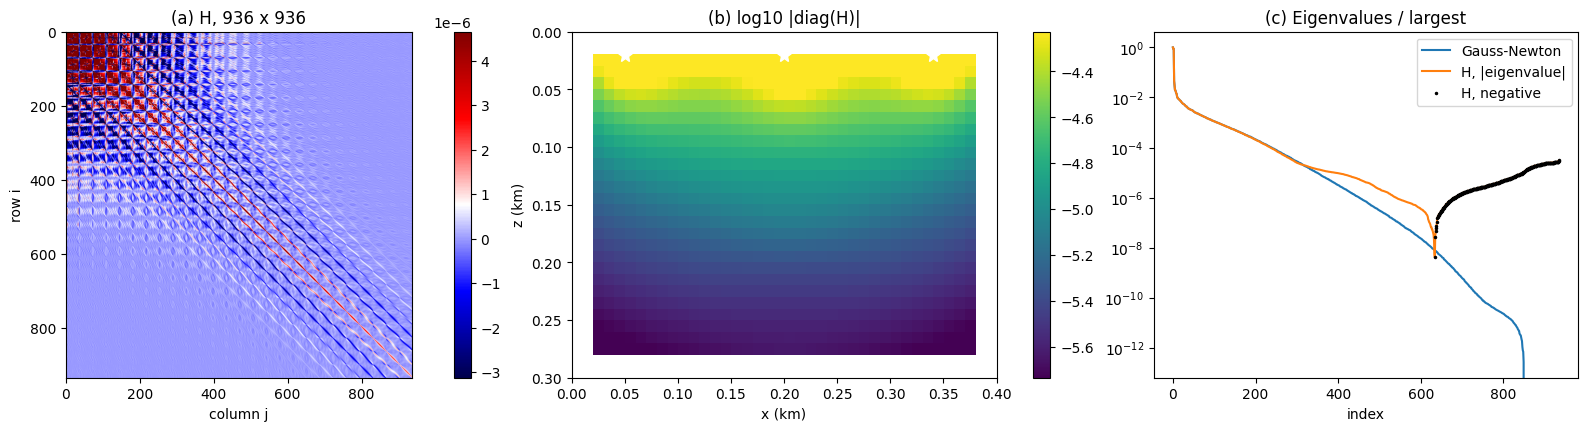

negative eigenvalues: H 302 (smallest -3.1e-05 of the largest), Gauss-Newton 86 (smallest -7.7e-11)


In [13]:
j = n // 2
(col,) = hessian_vector_product(s_eager, s_w, s_sources, s_receivers, [s_m0], [units[j]], s_loss,
                                route="forward")
col = col.flatten()[cells_t].double().cpu().numpy()
print(f"column {j} vs forward mode: {np.linalg.norm(H[:, j] - col) / np.linalg.norm(col):.1e}")

lam_h = np.linalg.eigvalsh(0.5 * (H + H.T))[::-1]
lam_gn = np.linalg.eigvalsh(0.5 * (GN + GN.T))[::-1]
diag = np.full((snz, snx), np.nan)
diag.flat[cells] = np.diag(H)
s_extent = [0, snx * dh / 1e3, snz * dh / 1e3, 0]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True)
lo, hi = np.percentile(H, [2, 98])
im = ax[0].imshow(H, cmap="seismic", vmin=lo, vmax=hi)
ax[0].set_title("(a) H, 936 x 936"); ax[0].set_xlabel("column j"); ax[0].set_ylabel("row i")
fig.colorbar(im, ax=ax[0])
log_diag = np.log10(np.abs(diag))
lo, hi = np.nanpercentile(log_diag[4:], [2, 98])                        # below the acquisition rows
im = ax[1].imshow(log_diag, cmap="viridis", vmin=lo, vmax=hi, extent=s_extent, aspect="auto")
ax[1].plot(s_sources[:, 0] * dh / 1e3, s_sources[:, 1] * dh / 1e3, "w*", ms=10)
ax[1].set_title("(b) log10 |diag(H)|"); ax[1].set_xlabel("x (km)"); ax[1].set_ylabel("z (km)")
fig.colorbar(im, ax=ax[1])
ax[2].semilogy(lam_gn / lam_gn[0], label="Gauss-Newton")
ax[2].semilogy(np.abs(lam_h) / lam_h[0], label="H, |eigenvalue|")
neg = lam_h < 0
ax[2].semilogy(np.flatnonzero(neg), np.abs(lam_h[neg]) / lam_h[0], "k.", ms=3, label="H, negative")
ax[2].set_title("(c) Eigenvalues / largest"); ax[2].set_xlabel("index"); ax[2].legend()
plt.show()
print(f"negative eigenvalues: H {int(neg.sum())} (smallest {lam_h.min() / lam_h[0]:.1e} of the largest), "
      f"Gauss-Newton {int((lam_gn < 0).sum())} (smallest {lam_gn.min() / lam_gn[0]:.1e})")

The cells are numbered row by row from the surface down, 36 per row. A cell's coupling with its
lateral neighbours therefore lies next to the diagonal of (a), and its coupling with the rows above
and below lies in bands 36 columns apart, which gives the striped pattern. The largest entries are
in the top-left block, which belongs to the shallow cells. The diagonal (b) decreases by more than
an order of magnitude from the surface to the bottom of the model and varies little laterally under
this dense receiver line; this depth decay is what a diagonal (illumination) preconditioner
compensates. The eigenvalues (c) of the Gauss-Newton matrix fall from 1 to $10^{-12}$ of the largest,
so most directions in the model are poorly constrained by these data; its negative eigenvalues, at
most about $10^{-10}$ of the largest, are round-off. The full Hessian follows the Gauss-Newton
spectrum for the well-constrained directions, but about a third of its eigenvalues are negative and
reach $-3\times10^{-5}$ of the largest, far above that round-off: the residual term is indefinite. A Newton
method on $\mathbf H$ therefore needs a conjugate-gradient loop that detects negative curvature, while a
Gauss-Newton method does not.

## 10. Which route to take

* For tests, small models and second derivatives of a loss with other autograd terms,
  `route="double_backward"` gives the exact product and every parameter the propagator
  differentiates; it keeps the time loop and its first backward on the tape.
* `route="forward"` is exact as well and gives $\mathbf J\mathbf h$ for equations without a Born twin; on
  this model it takes about three times the time of the double backward at two thirds of its
  memory.
* At production size, `route="difference"`, which `route="auto"` takes with `impl='c'`, boundary
  saving or the compiled step, gives $\mathbf H\mathbf h$ from two gradients with any `impl` and memory
  strategy; check `rel_step` once with a scan as in Section 5.
* For an equation with a Born twin (`AcousticBorn`), the first-order gradient of the Born system
  gives the exact $\mathbf H\mathbf h$ with `impl='c'` and boundary saving, at about the cost of two
  gradients; the compiled eager step runs it too.
* For a Gauss-Newton method, `gauss_newton_vector_product` (or the Born route of Section 6) gives
  $\mathbf J^{\mathsf T}\mathbf J\mathbf h$, which is positive semi-definite.
* For many directions (Hessian columns, probing vectors), `hessian_vector_products` runs them as
  copies of the survey, `batch` at a time. When memory bounds the batch, wrap the double backward
  in `slice_stencils()`: the same products from a graph three to four times smaller, at 1.4 to
  1.7 times the time.